# Experimento adicional: DINOv2-reg con Resize (64 → 224 px) y error por clase

## Objetivo
Evaluar el **mismo DINOv2-reg ViT-S/14 con registers**, usando la entrada EuroSAT de 64×64 ampliada a 224×224 mediante `Resize`, y medir:

1. Accuracy global y Macro-F1 en test.
2. Recall, F1 y tasa de error por cada clase.
3. Matriz de confusión y relación entre el desempeño por clase y sus errores.

**Importante:** este experimento no modifica el backbone ni introduce el *stem* nativo. Es la línea base de DINOv2-reg con resize, coherente con el notebook principal. La cabeza lineal es la única parte entrenable.

Se reutiliza el mismo split estratificado (70/15/15), la misma semilla de partición y la normalización ImageNet. Si se ejecuta desde Kaggle con el Output del notebook principal agregado como Input, se pueden reutilizar sus particiones y pesos. Si no, el notebook crea los splits y entrena la cabeza.

In [1]:
# 1. Instalación (si hace falta) e imports
# En Kaggle, ejecutar si torchvision / torch no están disponibles en el entorno.
import os, json, random, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader, TensorDataset
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             precision_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP = DEVICE == "cuda"
SEED, SEEDS = 42, [0, 1, 2]
BUDGETS = [0.10, 1.00]
MODEL_NAME = "dinov2_vits14_reg"
RES_IN = 224

In [2]:
# 2. Rutas y opción para reutilizar resultados del notebook principal
IN_KAGGLE = Path("/kaggle/working").exists()
ROOT = Path("/kaggle/working/dinov2_resize_experiment") if IN_KAGGLE else Path("./dinov2_resize_experiment")
DATA_DIR = Path("/kaggle/temp/datasets") if IN_KAGGLE else ROOT / "data"
ROOT.mkdir(parents=True, exist_ok=True); DATA_DIR.mkdir(parents=True, exist_ok=True)
RES = ROOT / "results"; RES.mkdir(exist_ok=True)

# Si agregaste el Output del notebook principal mediante "Add Input → Your Work",
# el notebook intentará encontrar splits y pesos guardados allí.
MAIN_OUTPUTS = []
if IN_KAGGLE:
    MAIN_OUTPUTS = list(Path("/kaggle/input").glob("*/dinov2_from_above"))
print("Dispositivo:", DEVICE)
print("Outputs previos encontrados:", [str(p) for p in MAIN_OUTPUTS])

Dispositivo: cuda
Outputs previos encontrados: []


In [3]:
# 3. EuroSAT RGB y partición idéntica a la del notebook principal
EUROSAT_CLASSES = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
                   "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
ds = torchvision.datasets.EuroSAT(root=str(DATA_DIR), download=True)
assert list(ds.classes) == EUROSAT_CLASSES
paths = [p for p, _ in ds.samples]
y = np.array([label for _, label in ds.samples])
assert len(y) == 27000

# Buscar el split guardado por el notebook principal; de lo contrario, recrearlo con la misma semilla.
split_path = next((p / "splits.json" for p in MAIN_OUTPUTS if (p / "splits.json").exists()), None)
if split_path:
    splits = json.loads(split_path.read_text())
    print("Split reutilizado:", split_path)
else:
    idx = np.arange(len(y))
    tr, tmp = train_test_split(idx, test_size=.30, stratify=y, random_state=SEED)
    va, te = train_test_split(tmp, test_size=.50, stratify=y[tmp], random_state=SEED)
    splits = {"train": tr.tolist(), "val": va.tolist(), "test": te.tolist()}
TR, VA, TE = (np.array(splits[k]) for k in ("train", "val", "test"))
print({k: len(splits[k]) for k in splits})

100%|██████████| 94.3M/94.3M [00:00<00:00, 272MB/s]


{'train': 18900, 'val': 4050, 'test': 4050}


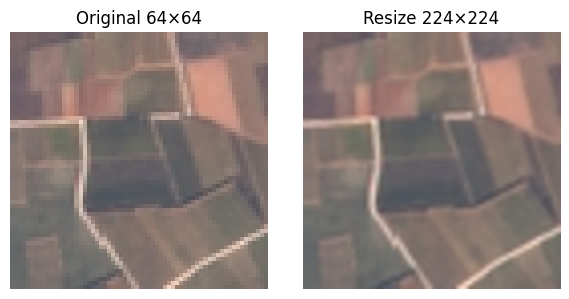

In [4]:
# 4. Preprocesamiento: Resize bicúbico de 64×64 a 224×224
IMNET = dict(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
resize_tf = T.Compose([
    T.Resize((RES_IN, RES_IN), interpolation=T.InterpolationMode.BICUBIC, antialias=True),
    T.ToTensor(),
    T.Normalize(**IMNET)
])

class EuroSATImages(Dataset):
    def __init__(self, indices, transform):
        self.indices, self.transform = list(indices), transform
    def __len__(self): return len(self.indices)
    def __getitem__(self, k):
        i = self.indices[k]
        im = Image.open(paths[i]).convert("RGB")
        return self.transform(im), int(y[i])

def loader(indices, shuffle=False, bs=128):
    return DataLoader(EuroSATImages(indices, resize_tf), batch_size=bs, shuffle=shuffle,
                      num_workers=2, pin_memory=AMP,
                      generator=torch.Generator().manual_seed(SEED))

def budget(frac, seed):
    if frac >= 1: return TR
    subset, _ = train_test_split(TR, train_size=frac, stratify=y[TR], random_state=seed)
    return np.sort(subset)

# Comprobación visual del resize
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
im = Image.open(paths[TE[0]]).convert("RGB")
ax[0].imshow(im); ax[0].set_title("Original 64×64"); ax[0].axis("off")
ax[1].imshow(im.resize((224,224), Image.Resampling.BICUBIC)); ax[1].set_title("Resize 224×224"); ax[1].axis("off")
plt.tight_layout()

In [5]:
# 5. Cargar DINOv2-reg congelado
dino = torch.hub.load("facebookresearch/dinov2", MODEL_NAME).eval().to(DEVICE)
for p in dino.parameters(): p.requires_grad_(False)
@torch.no_grad()
def extract_features(indices, batch_size=128):
    feats, labels = [], []
    dl = loader(indices, False, batch_size)
    for xb, yb in dl:
        xb = xb.to(DEVICE)
        with torch.autocast("cuda", enabled=AMP):
            z = dino.forward_features(xb)
            pooled = torch.cat([z["x_norm_clstoken"], z["x_norm_patchtokens"].mean(1)], dim=1)
        feats.append(pooled.float().cpu()); labels.append(yb)
    return torch.cat(feats), torch.cat(labels)

Xtr, Ytr = extract_features(TR)
Xva, Yva = extract_features(VA)
Xte, Yte = extract_features(TE)
print("Features:", Xtr.shape, Xva.shape, Xte.shape)

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_reg4_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_reg4_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 170MB/s]


Features: torch.Size([18900, 768]) torch.Size([4050, 768]) torch.Size([4050, 768])


In [6]:
# 6. Entrenar cabeza lineal con el protocolo del notebook principal
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def evaluate_head(head, X, Y, bs=512):
    head.eval()
    with torch.no_grad():
        logits = torch.cat([head(X[i:i+bs].to(DEVICE)).cpu() for i in range(0, len(X), bs)])
    pred = logits.argmax(1).numpy()
    return pred

def train_head(X, Y, seed, epochs=25, lr=1e-3):
    set_seed(seed)
    head = nn.Linear(768, 10).to(DEVICE)
    ds_train = TensorDataset(X, Y)
    dl = DataLoader(ds_train, batch_size=64, shuffle=True,
                    generator=torch.Generator().manual_seed(SEED))
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs*len(dl))
    best_f1, best_state = -1, None
    for ep in range(epochs):
        head.train()
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            loss = F.cross_entropy(head(xb), yb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        pv = evaluate_head(head, Xva, Yva)
        vf1 = f1_score(Yva.numpy(), pv, average="macro")
        if vf1 > best_f1:
            best_f1, best_state = vf1, {k:v.detach().cpu().clone() for k,v in head.state_dict().items()}
    head.load_state_dict(best_state)
    return head, best_f1

In [7]:
# 7. Evaluación global: accuracy y F1 macro para 10 % y 100 % de etiquetas
# Cachea pesos y resultados para no repetir entrenamientos.
rows, predictions = [], {}
for frac in BUDGETS:
    for seed in SEEDS:
        tag = f"resize_b{frac}_s{seed}"
        weight_file = RES / f"{tag}.pt"
        if weight_file.exists():
            head = nn.Linear(768,10).to(DEVICE)
            head.load_state_dict(torch.load(weight_file, map_location=DEVICE))
            print("Pesos recuperados:", tag)
        else:
            Xbudget, Ybudget = Xtr, Ytr
            if frac < 1:
                ix = budget(frac, seed)
                # Mapear índices globales del train a posiciones de Xtr
                pos = {int(v): j for j,v in enumerate(TR)}
                loc = np.array([pos[int(v)] for v in ix])
                Xbudget, Ybudget = Xtr[loc], Ytr[loc]
            head, best_val = train_head(Xbudget, Ybudget, seed)
            torch.save(head.state_dict(), weight_file)
        pred = evaluate_head(head, Xte, Yte)
        predictions[(frac,seed)] = pred
        rows.append({"modelo":"DINOv2-reg + Resize 64→224", "etiquetas":frac,
                     "semilla":seed, "accuracy":accuracy_score(Yte.numpy(),pred),
                     "f1_macro":f1_score(Yte.numpy(),pred,average="macro")})
df_global = pd.DataFrame(rows)
display(df_global.groupby("etiquetas")[["accuracy","f1_macro"]].agg(["mean","std"]).round(4))

accuracy         f1_macro        
              mean     std     mean     std
etiquetas                                  
0.1         0.9402  0.0023   0.9376  0.0022
1.0         0.9705  0.0008   0.9691  0.0008

In [8]:
# 8. Métricas por clase y tasa de error
# Reportamos resultados por semilla; luego el promedio para cada clase.
class_rows = []
for (frac, seed), pred in predictions.items():
    yt = Yte.numpy()
    report = classification_report(yt, pred, labels=range(10), target_names=EUROSAT_CLASSES,
                                   output_dict=True, zero_division=0)
    cm = confusion_matrix(yt, pred, labels=range(10))
    for c, name in enumerate(EUROSAT_CLASSES):
        support = int(cm[c].sum())
        correct = int(cm[c,c])
        fn = support - correct
        class_rows.append({
            "etiquetas":frac, "semilla":seed, "clase":name, "soporte":support,
            "aciertos":correct, "errores":fn,
            "tasa_error":fn/support if support else np.nan,
            "recall":report[name]["recall"], "precision":report[name]["precision"],
            "f1":report[name]["f1-score"]
        })
df_class = pd.DataFrame(class_rows)
class_summary = (df_class.groupby(["etiquetas","clase"])
                 .agg(soporte=("soporte","mean"), tasa_error_media=("tasa_error","mean"),
                      tasa_error_sd=("tasa_error","std"), recall=("recall","mean"),
                      precision=("precision","mean"), f1=("f1","mean"))
                 .reset_index())
display(class_summary.round(4))

,etiquetas,clase,soporte,tasa_error_media,tasa_error_sd,recall,precision,f1
0,0.1,AnnualCrop,450.0,0.0585,0.0013,0.9415,0.9374,0.9394
1,0.1,Forest,450.0,0.0311,0.0111,0.9689,0.9682,0.9685
2,0.1,HerbaceousVegetation,450.0,0.0615,0.0112,0.9385,0.9392,0.9389
3,0.1,Highway,375.0,0.0996,0.0086,0.9004,0.8991,0.8997
4,0.1,Industrial,375.0,0.0249,0.0132,0.9751,0.9575,0.9661
5,0.1,Pasture,300.0,0.0878,0.0077,0.9122,0.9014,0.9067
6,0.1,PermanentCrop,375.0,0.1031,0.0077,0.8969,0.9132,0.9049
7,0.1,Residential,450.0,0.0237,0.0130,0.9763,0.9643,0.9702
8,0.1,River,375.0,0.1040,0.0148,0.8960,0.9090,0.9024
9,0.1,SeaLake,450.0,0.0281,0.0013,0.9719,0.9872,0.9795


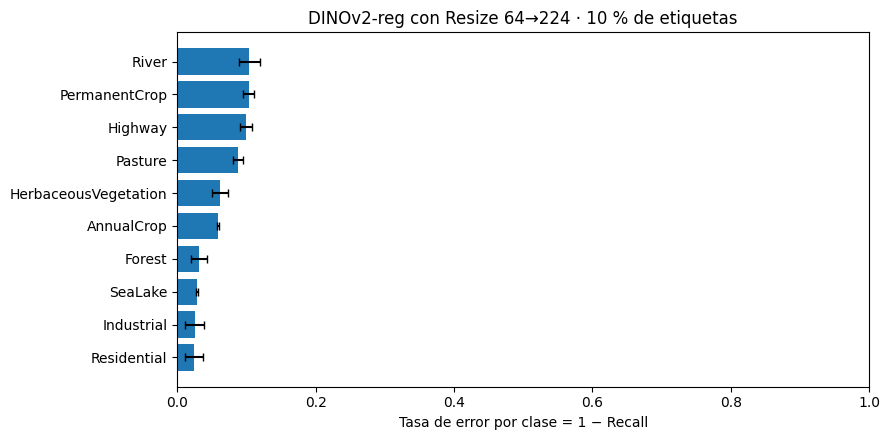

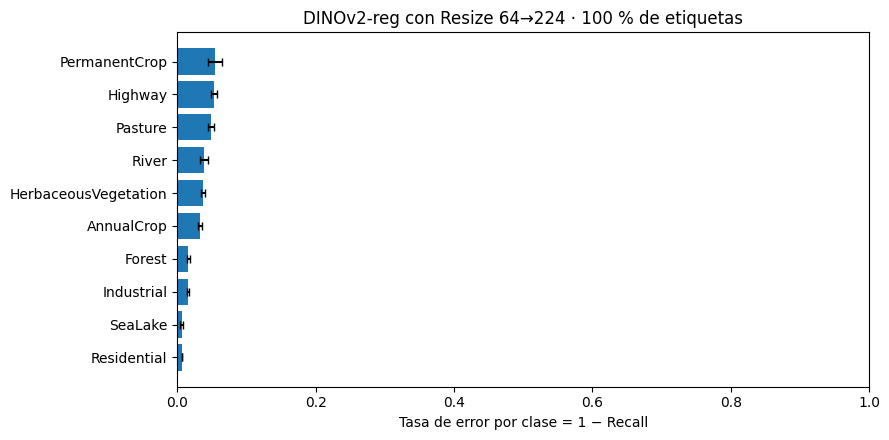

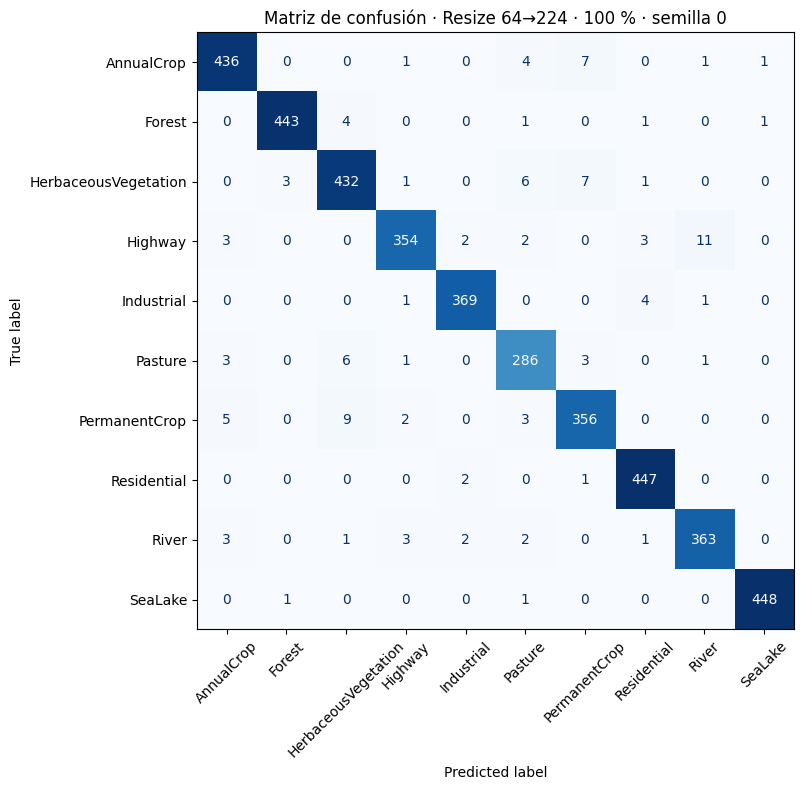

In [9]:
# 9. Gráficos: tasa de error por clase y matriz de confusión
for frac in BUDGETS:
    sub = class_summary[class_summary.etiquetas == frac].sort_values("tasa_error_media", ascending=True)
    plt.figure(figsize=(9,4.5))
    plt.barh(sub.clase, sub.tasa_error_media, xerr=sub.tasa_error_sd.fillna(0), capsize=3)
    plt.xlabel("Tasa de error por clase = 1 − Recall")
    plt.title(f"DINOv2-reg con Resize 64→224 · {int(frac*100)} % de etiquetas")
    plt.xlim(0,1); plt.tight_layout(); plt.show()

# Matriz de confusión para 100 % de etiquetas, semilla 0
p = predictions[(1.0,0)]
cm = confusion_matrix(Yte.numpy(), p, labels=range(10))
disp = ConfusionMatrixDisplay(cm, display_labels=EUROSAT_CLASSES)
fig, ax = plt.subplots(figsize=(9,8))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues", values_format="d")
ax.set_title("Matriz de confusión · Resize 64→224 · 100 % · semilla 0")
plt.tight_layout()

In [10]:
# 10. Clases con mayor error y exportación de resultados
for frac in BUDGETS:
    print(f"\n{int(frac*100)} % de etiquetas — clases con mayor tasa de error:")
    display(class_summary[class_summary.etiquetas == frac]
            .sort_values("tasa_error_media", ascending=False)
            [["clase","soporte","tasa_error_media","recall","precision","f1"]]
            .head(10).round(4))

df_global.to_csv(RES/"resize_metricas_globales.csv", index=False)
df_class.to_csv(RES/"resize_metricas_por_clase_semilla.csv", index=False)
class_summary.to_csv(RES/"resize_resumen_por_clase.csv", index=False)
print("Guardado en:", RES)


10 % de etiquetas — clases con mayor tasa de error:


,clase,soporte,tasa_error_media,recall,precision,f1
8,River,375.0,0.1040,0.8960,0.9090,0.9024
6,PermanentCrop,375.0,0.1031,0.8969,0.9132,0.9049
3,Highway,375.0,0.0996,0.9004,0.8991,0.8997
5,Pasture,300.0,0.0878,0.9122,0.9014,0.9067
2,HerbaceousVegetation,450.0,0.0615,0.9385,0.9392,0.9389
0,AnnualCrop,450.0,0.0585,0.9415,0.9374,0.9394
1,Forest,450.0,0.0311,0.9689,0.9682,0.9685
9,SeaLake,450.0,0.0281,0.9719,0.9872,0.9795
4,Industrial,375.0,0.0249,0.9751,0.9575,0.9661
7,Residential,450.0,0.0237,0.9763,0.9643,0.9702



100 % de etiquetas — clases con mayor tasa de error:


,clase,soporte,tasa_error_media,recall,precision,f1
16,PermanentCrop,375.0,0.0551,0.9449,0.9560,0.9504
13,Highway,375.0,0.0533,0.9467,0.9700,0.9582
15,Pasture,300.0,0.0489,0.9511,0.9396,0.9453
18,River,375.0,0.0382,0.9618,0.9609,0.9613
12,HerbaceousVegetation,450.0,0.0370,0.9630,0.9566,0.9598
10,AnnualCrop,450.0,0.0326,0.9674,0.9688,0.9681
11,Forest,450.0,0.0156,0.9844,0.9867,0.9855
14,Industrial,375.0,0.0151,0.9849,0.9814,0.9831
17,Residential,450.0,0.0067,0.9933,0.9781,0.9857
19,SeaLake,450.0,0.0067,0.9933,0.9941,0.9937


Guardado en: dinov2_resize_experiment/results
